CÁLCULO PASO A PASO DE LA TDF PARA f[n] = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Longitud de la secuencia (N): 10
Fórmula: F[k] = ∑_{n=0}^{N-1} f[n] * e^(-j * 2π * k * n / N)

---> EVALUANDO PARA k = 0:
  n=0: f[0] * e^(-j*2π*0*0/10) = 0 * (1.00 + 0.00j) = 0.00 + 0.00j
  n=1: f[1] * e^(-j*2π*0*1/10) = 1 * (1.00 + 0.00j) = 1.00 + 0.00j
  n=2: f[2] * e^(-j*2π*0*2/10) = 2 * (1.00 + 0.00j) = 2.00 + 0.00j
  n=3: f[3] * e^(-j*2π*0*3/10) = 3 * (1.00 + 0.00j) = 3.00 + 0.00j
  n=4: f[4] * e^(-j*2π*0*4/10) = 4 * (1.00 + 0.00j) = 4.00 + 0.00j
  n=5: f[5] * e^(-j*2π*0*5/10) = 5 * (1.00 + 0.00j) = 5.00 + 0.00j
  n=6: f[6] * e^(-j*2π*0*6/10) = 6 * (1.00 + 0.00j) = 6.00 + 0.00j
  n=7: f[7] * e^(-j*2π*0*7/10) = 7 * (1.00 + 0.00j) = 7.00 + 0.00j
  n=8: f[8] * e^(-j*2π*0*8/10) = 8 * (1.00 + 0.00j) = 8.00 + 0.00j
  n=9: f[9] * e^(-j*2π*0*9/10) = 9 * (1.00 + 0.00j) = 9.00 + 0.00j
  [RESULTADO F[0]] = 45.00 + 0.00j
  [Magnitud] = 45.0000 | [Fase] = 0.00° (0.0000 rad)

---> EVALUANDO PARA k = 1:
  n=0: f[0] * e^(-j

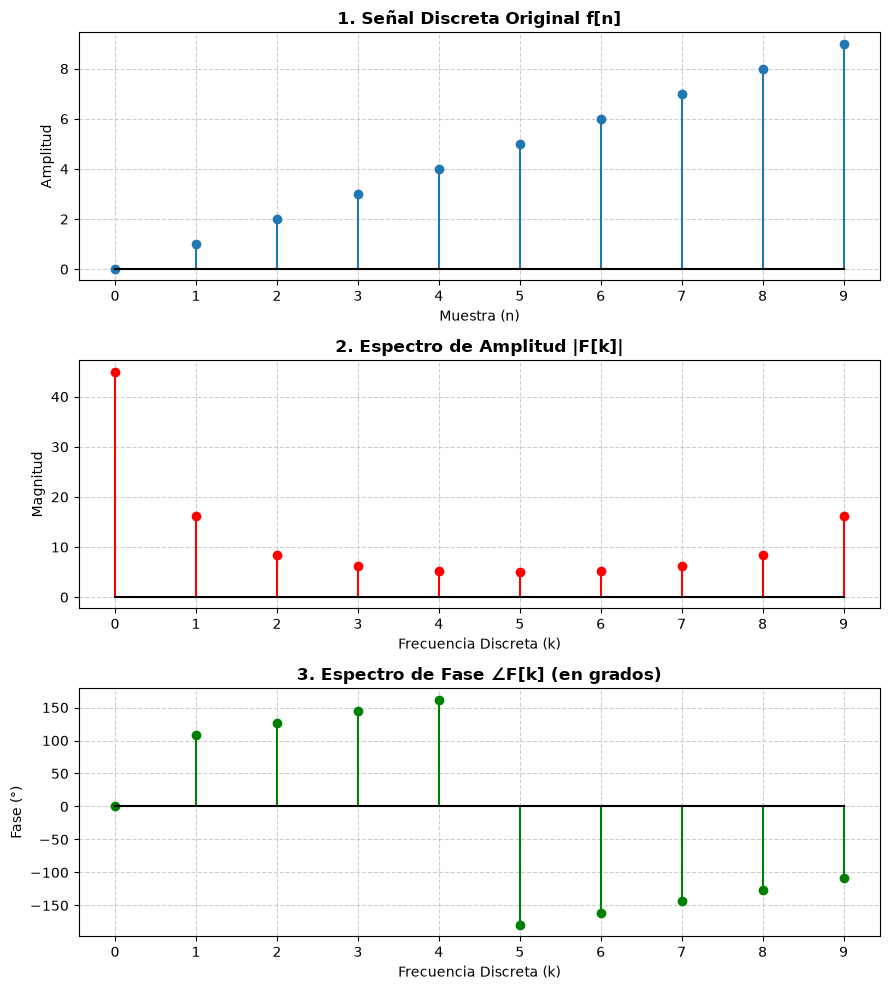

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def resolver_tdf_paso_a_paso(f):
    N = len(f)
    print("=" * 70)
    print(f"CÁLCULO PASO A PASO DE LA TDF PARA f[n] = {f}")
    print(f"Longitud de la secuencia (N): {N}")
    print("Fórmula: F[k] = ∑_{n=0}^{N-1} f[n] * e^(-j * 2π * k * n / N)")
    print("=" * 70)

    F = np.zeros(N, dtype=complex)
    tabla_datos = []

    # 1. CÁLCULO PASO A PASO
    for k in range(N):
        print(f"\n---> EVALUANDO PARA k = {k}:")
        suma_terminos = 0
        
        for n in range(N):
            # Ángulo en radianes: -2 * pi * k * n / N
            angulo = -2 * np.pi * k * n / N
            exponencial = np.exp(1j * angulo)
            termino = f[n] * exponencial
            suma_terminos += termino

            # Mostrar operación detallada por término n
            print(f"  n={n}: f[{n}] * e^(-j*2π*{k}*{n}/{N}) = {f[n]} * ({exponencial.real:.2f} + {exponencial.imag:.2f}j) = {termino.real:.2f} + {termino.imag:.2f}j")

        F[k] = suma_terminos
        mag = np.abs(F[k])
        fase_rad = np.angle(F[k])
        fase_deg = np.rad2deg(fase_rad)

        print(f"  [RESULTADO F[{k}]] = {F[k].real:.2f} + {F[k].imag:.2f}j")
        print(f"  [Magnitud] = {mag:.4f} | [Fase] = {fase_deg:.2f}° ({fase_rad:.4f} rad)")

        # Guardar en la estructura para la tabla
        tabla_datos.append({
            "k": k,
            "f[n] Real": round(F[k].real, 4),
            "f[n] Imag": round(F[k].imag, 4),
            "F[k] Complejo": f"{F[k].real:.2f} + {F[k].imag:.2f}j",
            "Amplitud |F[k]|": round(mag, 4),
            "Fase (rad)": round(fase_rad, 4),
            "Fase (grados)": round(fase_deg, 2)
        })

    # 2. TABLA DE RESULTADOS
    df = pd.DataFrame(tabla_datos)
    print("\n" + "=" * 70)
    print("TABLA RESUMEN DE LA TRANSFORMADA DISCRETA DE FOURIER")
    print("=" * 70)
    print(df.to_string(index=False))

    # 3. GRAFICACIÓN DE LOS ESPECTROS
    fig, axs = plt.subplots(3, 1, figsize=(9, 10))

    # Gráfica 1: Señal original f[n]
    axs[0].stem(range(N), f, basefmt="k-")
    axs[0].set_title("1. Señal Discreta Original f[n]", fontsize=12, fontweight='bold')
    axs[0].set_xlabel("Muestra (n)")
    axs[0].set_ylabel("Amplitud")
    axs[0].set_xticks(range(N))
    axs[0].grid(True, linestyle="--", alpha=0.6)

    # Gráfica 2: Espectro de Amplitud |F[k]|
    axs[1].stem(range(N), df["Amplitud |F[k]|"], linefmt="r-", markerfmt="ro", basefmt="k-")
    axs[1].set_title("2. Espectro de Amplitud |F[k]|", fontsize=12, fontweight='bold')
    axs[1].set_xlabel("Frecuencia Discreta (k)")
    axs[1].set_ylabel("Magnitud")
    axs[1].set_xticks(range(N))
    axs[1].grid(True, linestyle="--", alpha=0.6)

    # Gráfica 3: Espectro de Fase en Grados ∠F[k]
    axs[2].stem(range(N), df["Fase (grados)"], linefmt="g-", markerfmt="go", basefmt="k-")
    axs[2].set_title("3. Espectro de Fase ∠F[k] (en grados)", fontsize=12, fontweight='bold')
    axs[2].set_xlabel("Frecuencia Discreta (k)")
    axs[2].set_ylabel("Fase (°)")
    axs[2].set_xticks(range(N))
    axs[2].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

# Secuencia del ejercicio f[n] = [-1, 1, 0, 2]
secuencia = [0,1,2,3,4,5,6,7,8,9]
resolver_tdf_paso_a_paso(secuencia)